Max absolute correlation with true sources (ICA): [1.    1.    0.901]


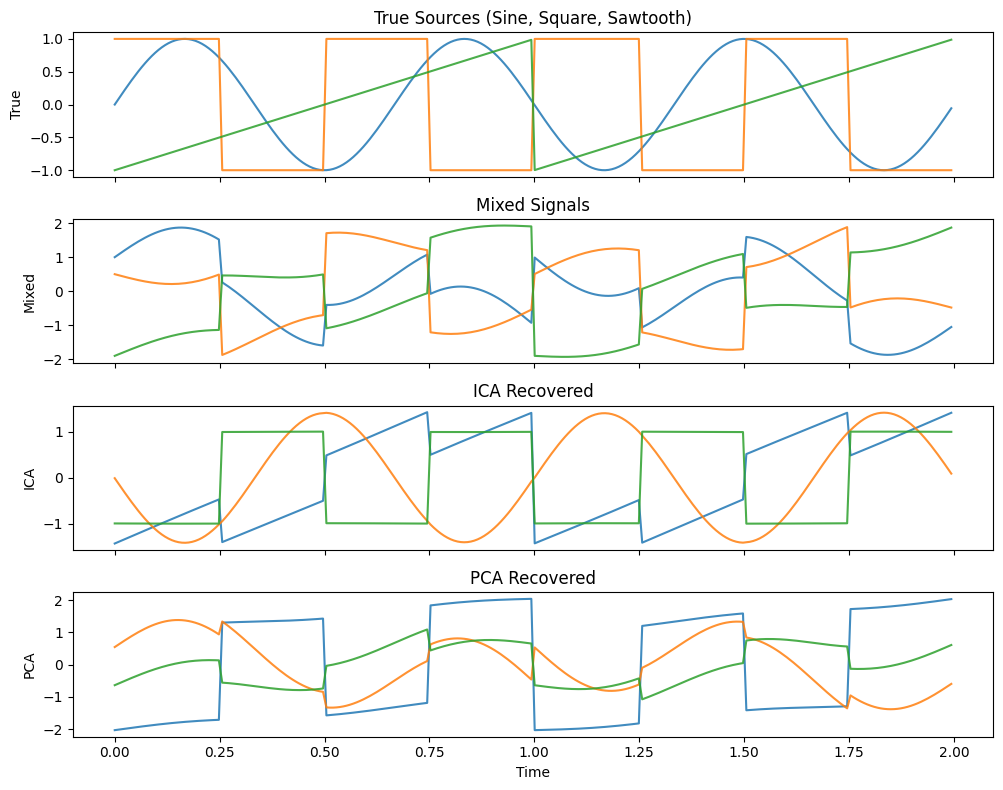

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import FastICA, PCA

t = np.linspace(0, 8, 1000)
s1 = np.sin(2 * np.pi * 1.5 * t)
s2 = signal.square(2 * np.pi * 2.0 * t)
s3 = signal.sawtooth(2 * np.pi * 1.0 * t)
S = np.c_[s1, s2, s3]

A = np.array([[1.0, 0.6, -0.4], [-0.5, 1.2, 0.7], [0.3, -0.8, 1.1]])
X = S @ A.T

ica = FastICA(n_components=3, random_state=42).fit(X)
S_ica = ica.transform(X)
S_pca = PCA(n_components=3).fit_transform(X)

corrs = [max(abs(np.corrcoef(S[:, i], S_ica[:, j])[0, 1]) for j in range(3)) for i in range(3)]
print("Max absolute correlation with true sources (ICA):", np.round(corrs, 3))

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for i, (arr, title) in enumerate([
    (S, "True Sources (Sine, Square, Sawtooth)"),
    (X, "Mixed Signals"),
    (S_ica, "ICA Recovered"),
    (S_pca, "PCA Recovered")
]):
    for c in range(3):
        axes[i].plot(t[:250], arr[:250, c], alpha=0.85, label=f"Ch {c+1}")
    axes[i].set_ylabel(title.split()[0]); axes[i].set_title(title)
axes[-1].set_xlabel("Time"); plt.tight_layout(); plt.show()